<a href="https://colab.research.google.com/github/PiyushAgrawal05/Phoneme-Recognition-Model-WavLM-ConBiMamba-LoRA-MoE/blob/main/Phoneme_Recognition_Model_WavLM_ConBiMamba_LoRA_MoE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Phase 1: Environment Setup & Authentication


In [ ]:
# # cell 1
# from google.colab import drive
# drive.mount('/content/drive')

Mounted at /content/drive


### Cell 2 & 3: Dependency Installations, Storage Configuration & Authentication
* **Purpose:** Installs external libraries required for the pipeline, configures flexible model checkpoint storage (Hugging Face Hub vs. Google Drive), and creates smart helper functions for loading/saving weights.
* **Operations:**
  * Installs `datasets`, `torchaudio`, `huggingface_hub`, `jiwer`, `g2p_en`, `gradio`, and `transformers`.
  * Authenticates with Hugging Face via OAuth.
  * Defines a `STORAGE_MODE` toggle (`"huggingface"` or `"gdrive"`).
  * Dynamically detects the logged-in user to set a personal upload repository, while maintaining a fixed source for the official pretrained weights.
  * Initializes `load_checkpoint()` and `save_and_upload_checkpoint()` to seamlessly handle file I/O across the rest of the notebook without hardcoded paths.

In [2]:
# Cell 2: Install Required Dependencies
!pip install -q datasets torchaudio huggingface_hub jiwer g2p_en gradio
!pip install -q transformers

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# Cell 3: Storage Configuration, Authentication & Helper Functions
import os
import torch

# --- USER CONFIGURATION ---
# Set to "huggingface" or "gdrive"
STORAGE_MODE = "huggingface"
PRETRAINED_REPO = "hsuyip05/wavlm-conbimamba-lora-moe" # Official source of truth

if STORAGE_MODE == "gdrive":
    from google.colab import drive
    drive.mount('/content/drive')
    GDRIVE_DIR = "/content/drive/MyDrive/"
    os.makedirs(GDRIVE_DIR, exist_ok=True)
    print(f"✅ Storage Mode: Google Drive. Saving to {GDRIVE_DIR}")

elif STORAGE_MODE == "huggingface":
    from huggingface_hub import login, hf_hub_download, HfApi
    login()
    hf_api = HfApi()
    current_user = hf_api.whoami().get("name", "")
    USER_UPLOAD_REPO = f"{current_user}/wavlm-conbimamba-lora-moe"
    print(f"✅ Storage Mode: Hugging Face.")
    print(f"Logged in as: {current_user}")
    print(f"Pulling pretrained weights from: https://huggingface.co/{PRETRAINED_REPO}")
    print(f"Pushing new checkpoints to  : https://huggingface.co/{USER_UPLOAD_REPO}")
else:
    raise ValueError("STORAGE_MODE must be strictly 'huggingface' or 'gdrive'")

# --- SMART HELPER FUNCTIONS ---
def load_checkpoint(filename):
    """Fetches the checkpoint path based on the selected storage mode."""
    if STORAGE_MODE == "gdrive":
        path = f"{GDRIVE_DIR}/{filename}"
        if not os.path.exists(path):
            raise FileNotFoundError(f"Missing {filename} in {GDRIVE_DIR}. Ensure you trained Stage 1!")
        return path
    elif STORAGE_MODE == "huggingface":
        # Always pull the baseline from the original author's repo to prevent errors
        return hf_hub_download(repo_id=PRETRAINED_REPO, filename=filename)

def save_and_upload_checkpoint(state_dict, filename):
    """Saves the checkpoint and automatically uploads it if using HF Hub."""
    if STORAGE_MODE == "gdrive":
        path = f"{GDRIVE_DIR}/{filename}"
        torch.save(state_dict, path)
        print(f"Checkpoint successfully saved to Google Drive: {path}")
    elif STORAGE_MODE == "huggingface":
        torch.save(state_dict, filename)
        hf_api.create_repo(repo_id=USER_UPLOAD_REPO, repo_type="model", exist_ok=True)
        hf_api.upload_file(
            path_or_fileobj=filename,
            path_in_repo=filename,
            repo_id=USER_UPLOAD_REPO,
            repo_type="model"
        )
        print(f"Checkpoint successfully saved and pushed to https://huggingface.co/{USER_UPLOAD_REPO}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


✅ Storage Mode: Hugging Face.
Logged in as: hsuyip05
Pulling pretrained weights from: https://huggingface.co/hsuyip05/wavlm-conbimamba-lora-moe
Pushing new checkpoints to  : https://huggingface.co/hsuyip05/wavlm-conbimamba-lora-moe


### Cell 4: NLTK Tokenizer Resource Download
* **Purpose:** Downloads linguistic resources required by the G2P (Grapheme-to-Phoneme) engine.
* **Operations:** Downloads `punkt`, `punkt_tab`, `averaged_perceptron_tagger`, `averaged_perceptron_tagger_eng`, and `cmudict` packages via NLTK.

In [4]:
# Cell 4: Download NLTK Support Packages
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('cmudict')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package cmudict to /root/nltk_data...
[nltk_data]   Unzipping corpora/cmudict.zip.


True

## Phase 2: Vocabulary & Data Ingestion Pipeline

### Cell 5: Vocabulary Definition & Label Normalization
* **Purpose:** Constructs the deterministic mapping between CMU ARPAbet phonemes and integer indices.
* **Operations:** Strictly reserves index `0` for the CTC `<blank>` token, maps 39 CMU ARPAbet phonemes to indices `1–39`, and assigns index `40` to `<unk>` (Total classes: 41). Strips stress digits from phoneme strings.

In [5]:
# Cell 5: Vocabulary Definition and Mapping (Fixed 41-Class Indexing)
import re

cmu_phonemes = [
    "AA", "AE", "AH", "AO", "AW", "AY", "B", "CH", "D", "DH", "EH", "ER",
    "EY", "F", "G", "HH", "IH", "IY", "JH", "K", "L", "M", "N", "NG", "OW",
    "OY", "P", "R", "S", "SH", "T", "TH", "UH", "UW", "V", "W", "Y", "Z", "ZH"
]

# Strictly reserve 0 for CTC <blank> and 40 for <unk>
vocab_dict = {"<blank>": 0}
for i, phn in enumerate(cmu_phonemes):
    vocab_dict[phn] = i + 1
vocab_dict["<unk>"] = 40

id_to_vocab = {v: k for k, v in vocab_dict.items()}

def clean_phoneme(phn):
    phn = re.sub(r'\d+', '', str(phn)).strip().upper()
    return phn if phn in vocab_dict else "<unk>"

print(f"Vocabulary initialized with {len(vocab_dict)} classes (Blank index: {vocab_dict['<blank>']}, Unk index: {vocab_dict['<unk>']}).")

Vocabulary initialized with 41 classes (Blank index: 0, Unk index: 40).


### Cell 6: Dataset Streaming & Stratified Partitioning
* **Purpose:** Initializes memory-efficient audio data streams.
* **Operations:** Loads native LibriSpeech (`train.100`) and non-native SpeechOcean762 (`train`) in streaming mode, and splits the `scripted` partition of L2-Arctic into strict 80/10/10 Train-Validation-Test `IterableDataset` streams.

In [6]:
# Cell 6: Load and Split Streaming Datasets
from datasets import load_dataset

# 1. LibriSpeech (Native English Baseline)
libri_stream = load_dataset("openslr/librispeech_asr", "clean", split="train.100", streaming=True)

# 2. SpeechOcean762 (Non-Native Expansion)
so762_stream = load_dataset("mispeech/speechocean762", split="train", streaming=True)

# 3. L2 Arctic (Non-Native Target Domain - Split into Train, Validation, and Test)
# Load the full "scripted" dataset (fits easily in memory)
l2_dataset = load_dataset("KoelLabs/L2Arctic", split="scripted")

# Create a randomized 80% Train / 20% Temp split
l2_train_test = l2_dataset.train_test_split(test_size=0.2, seed=42)

# Split the 20% Temp into 10% Validation / 10% Test
l2_val_test = l2_train_test['test'].train_test_split(test_size=0.5, seed=42)

# Convert them back to streaming (IterableDataset) to match your pipeline's format
l2_train_stream = l2_train_test['train'].to_iterable_dataset()
l2_val_stream   = l2_val_test['train'].to_iterable_dataset()
l2_test_stream  = l2_val_test['test'].to_iterable_dataset()

# Quick diagnostic check
sample = next(iter(so762_stream))
print("Audio array shape:", sample["audio"]["array"].shape)
print("Sampling rate:", sample["audio"]["sampling_rate"])

README.md:   0%|          | 0.00/11.0k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/7.55k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.93k [00:00<?, ?B/s]

data/spontaneous-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 50.0MB            

... (2 outputs left out)

data/scripted-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating spontaneous split:   0%|          | 0/22 [00:00<?, ? examples/s]

Generating scripted split:   0%|          | 0/3599 [00:00<?, ? examples/s]

Audio array shape: (41280,)
Sampling rate: 16000


In [7]:
# Grab one sample from each stream
libri_sample = next(iter(libri_stream))
so762_sample = next(iter(so762_stream))
l2_sample = next(iter(l2_train_stream))

print("LibriSpeech keys:", libri_sample.keys())
print("SpeechOcean keys:", so762_sample.keys())
print("L2 Arctic keys:", l2_sample.keys())

LibriSpeech keys: dict_keys(['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
SpeechOcean keys: dict_keys(['accuracy', 'completeness', 'fluency', 'prosodic', 'text', 'total', 'words', 'speaker', 'gender', 'age', 'audio'])
L2 Arctic keys: dict_keys(['audio', 'ipa', 'text', 'g2p', 'speaker_code', 'speaker_gender', 'speaker_native_language'])


### Cell 7: Audio Feature Extraction Pipeline
* **Purpose:** Configures spectral audio transformations and inspects dataset sample keys.
* **Operations:** Initializes a 16kHz, 80-channel `MelSpectrogram` transform (`n_fft=400`, `hop_length=160`) with logarithmic clamping (`min=1e-5`) to prevent FP16 gradient underflow, and verifies L2-Arctic `ipa` vs `g2p` fields.

In [8]:
# Cell 7: Feature Extraction Setup
import torch
import torchaudio

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=16000, n_mels=80, n_fft=400, hop_length=160
).to(device)
hop_length = mel_transform.hop_length

def extract_features(audio_array):
    tensor = torch.tensor(audio_array, dtype=torch.float32)
    if tensor.ndim == 1:
        tensor = tensor.unsqueeze(0)
    mel_spec = mel_transform(tensor.to(device))
    log_mel = torch.log(mel_spec.clamp(min=1e-5))
    return log_mel.squeeze(0).transpose(0, 1).cpu()
print("L2 sample 'ipa':", l2_sample["ipa"])
print("L2 sample 'g2p':", l2_sample["g2p"])

L2 sample 'ipa': maɪˈaɪdiˈʌwɔˈzdæˈthiˈʊˈdəhæˈvmɔˈɹɪˈnfluʌnsɔvɝðʌneɪˈtɪvs
L2 sample 'g2p': maɪaɪdiʌwɑzðæthiwʊdhævmɔɹɪnfluʌnsoʊvɝðʌneɪtɪvz


### Cell 8: Phonetic Transcription & Perceived IPA-to-ARPAbet Mapping
* **Purpose:** Standardizes phonetic targets across all datasets using true perceived acoustics.
  * Maps 100% of L2-Arctic's perceived IPA symbols (including taps `ɾ`, non-rhotic vowels `ɜ`, `ɒ`, `ɐ`, and palatal/velar allophones) to ARPAbet so no spoken phones are silently dropped from ground truth labels.
* **Operations:** Uses `g2p_en` for native LibriSpeech, human-annotated phone lists for SpeechOcean762, and a custom longest-first greedy IPA-to-ARPAbet parser on L2-Arctic's `ipa` column so the model learns actual spoken non-native acoustics rather than canonical prompts.

In [9]:
# Cell 8: Complete Perceived IPA-to-ARPAbet Mapping (Including All L2 Allophones)
from g2p_en import G2p
g2p = G2p()

# Comprehensive longest-first IPA mapping covering all L2-Arctic human transcription symbols
IPA_TO_ARPABET = [
    ("tʃ", "CH"), ("dʒ", "JH"), ("aɪ", "AY"), ("aʊ", "AW"), ("ɔɪ", "OY"),
    ("eɪ", "EY"), ("oʊ", "OW"), ("əʊ", "OW"), ("ɝ", "ER"), ("ɚ", "ER"),
    ("ɜɹ", "ER"), ("əɹ", "ER"), ("ɑ", "AA"), ("ɒ", "AA"), ("a", "AA"),
    ("æ", "AE"), ("ʌ", "AH"), ("ə", "AH"), ("ɐ", "AH"), ("ɜ", "ER"),
    ("ɔ", "AO"), ("ɛ", "EH"), ("e", "EY"), ("ɪ", "IH"), ("i", "IY"),
    ("ʊ", "UH"), ("u", "UW"), ("ʉ", "UW"), ("o", "OW"),
    ("b", "B"), ("d", "D"), ("ɾ", "D"), ("ð", "DH"), ("f", "F"),
    ("ɡ", "G"), ("g", "G"), ("h", "HH"), ("ɦ", "HH"), ("x", "HH"),
    ("j", "Y"), ("k", "K"), ("l", "L"), ("ɫ", "L"), ("m", "M"),
    ("n", "N"), ("ɲ", "N"), ("ŋ", "NG"), ("p", "P"), ("ɹ", "R"),
    ("r", "R"), ("ɻ", "R"), ("s", "S"), ("ʃ", "SH"), ("t", "T"),
    ("ʔ", "T"), ("θ", "TH"), ("v", "V"), ("w", "W"), ("ʍ", "W"),
    ("z", "Z"), ("ʒ", "ZH")
]

def ipa_to_arpabet_ids(ipa_str):
    # Strip stress marks, length colons, tie bars, and spaces
    s = re.sub(r'[ˈˌːˑ͜͡\s]', '', str(ipa_str))
    ids = []
    i = 0
    while i < len(s):
        matched = False
        for ipa_tok, arpa_tok in IPA_TO_ARPABET:
            if s.startswith(ipa_tok, i):
                ids.append(vocab_dict[arpa_tok])
                i += len(ipa_tok)
                matched = True
                break
        if not matched:
            i += 1
    return ids

def process_libri(sample):
    raw_phones = g2p(sample["text"])
    labels = [vocab_dict[clean_phoneme(p)] for p in raw_phones if p.isalpha() and clean_phoneme(p) != "<unk>"]
    return {"raw_audio": sample["audio"]["array"], "labels": labels, "speaker": str(sample["speaker_id"])}

def process_so762(sample):
    raw_phones = [phone for word in sample["words"] for phone in word["phones"]]
    labels = [vocab_dict[clean_phoneme(p)] for p in raw_phones if clean_phoneme(p) != "<unk>"]
    return {"raw_audio": sample["audio"]["array"], "labels": labels, "speaker": str(sample["speaker"])}

def process_l2(sample):
    labels = ipa_to_arpabet_ids(sample["ipa"])
    return {"raw_audio": sample["audio"]["array"], "labels": labels, "speaker": str(sample["speaker_code"])}

libri_ready = libri_stream.map(process_libri, remove_columns=['file', 'audio', 'text', 'speaker_id', 'chapter_id', 'id'])
so762_ready = so762_stream.map(process_so762, remove_columns=['accuracy', 'completeness', 'fluency', 'prosodic', 'text', 'total', 'words', 'speaker', 'gender', 'age', 'audio'])
l2_train_ready = l2_train_stream.map(process_l2, remove_columns=['audio', 'ipa', 'text', 'g2p', 'speaker_code', 'speaker_gender', 'speaker_native_language'])
l2_val_ready   = l2_val_stream.map(process_l2, remove_columns=['audio', 'ipa', 'text', 'g2p', 'speaker_code', 'speaker_gender', 'speaker_native_language'])
l2_test_ready  = l2_test_stream.map(process_l2, remove_columns=['audio', 'ipa', 'text', 'g2p', 'speaker_code', 'speaker_gender', 'speaker_native_language'])

print("Complete L2 IPA-to-ARPAbet pipeline updated.")

Complete L2 IPA-to-ARPAbet pipeline updated.


### Cell 9: Dynamic Batch Collation
* **Purpose:** Handles variable-length sequence batching for PyTorch's CTC loss.
* **Operations:** Converts raw audio arrays and phoneme label lists into tensors, zero-padding both to the maximum sequence length in the mini-batch while returning exact unpadded `input_lengths` and `target_lengths`.

In [10]:
# Cell 9: Collate Function for Variable Sequence Lengths
import numpy as np
from torch.nn.utils.rnn import pad_sequence

def ctc_collate_fn(batch):
    features_list = []
    labels_list = []
    input_lengths = []
    target_lengths = []

    for sample in batch:
        feat_tensor = torch.from_numpy(np.array(sample["raw_audio"], dtype=np.float32))
        features_list.append(feat_tensor)
        input_lengths.append(feat_tensor.shape[0])

        lbl_tensor = torch.tensor(sample["labels"], dtype=torch.long)
        labels_list.append(lbl_tensor)
        target_lengths.append(len(lbl_tensor))

    padded_features = pad_sequence(features_list, batch_first=True, padding_value=0.0)
    padded_labels = pad_sequence(labels_list, batch_first=True, padding_value=0)

    input_lengths = torch.tensor(input_lengths, dtype=torch.long)
    target_lengths = torch.tensor(target_lengths, dtype=torch.long)

    return padded_features, padded_labels, input_lengths, target_lengths

### Cell 10: Stream Filtering & DataLoader Initialization
* **Purpose:** Generates the final PyTorch DataLoaders.
* **Operations:** Filters out empty or oversized audio clips (`> 160,000` samples / 10 seconds) and interleaves LibriSpeech and SpeechOcean762 streams (`buffer_size=1000`, `batch_size=4`) for Stage 1 pre-training alongside L2-Arctic fine-tuning and evaluation loaders.

In [11]:
# Cell 10: Stream Filtering and DataLoader Construction
from datasets import interleave_datasets
from torch.utils.data import DataLoader

MAX_SAMPLES = 160000

def filter_length(sample):
    return len(sample["raw_audio"]) <= MAX_SAMPLES and len(sample["labels"]) > 0

l2_train_filtered = l2_train_ready.filter(filter_length)
l2_val_filtered   = l2_val_ready.filter(filter_length)
l2_test_filtered  = l2_test_ready.filter(filter_length)
libri_filtered    = libri_ready.filter(filter_length)
so762_filtered    = so762_ready.filter(filter_length)

pretrain_stream = interleave_datasets([libri_filtered, so762_filtered]).shuffle(seed=42, buffer_size=1000)
l2_train_stream_shuffled = l2_train_filtered.shuffle(seed=42, buffer_size=1000)

batch_size = 4
pretrain_loader = DataLoader(pretrain_stream, batch_size=batch_size, collate_fn=ctc_collate_fn)
finetune_loader = DataLoader(l2_train_stream_shuffled, batch_size=batch_size, collate_fn=ctc_collate_fn)
val_loader      = DataLoader(l2_val_filtered, batch_size=batch_size, collate_fn=ctc_collate_fn)
test_loader     = DataLoader(l2_test_filtered, batch_size=batch_size, collate_fn=ctc_collate_fn)

print("DataLoaders compiled with input-length validation.")

DataLoaders compiled with input-length validation.


## Phase 3: Model Architecture & Regularization

### Cell 11: Hybrid WavLM + ConBiMamba + Frame-Level LoRA-MoE Architecture
* **Purpose:** Implements the complete Pure-Acoustic Phoneme Recognition architecture in a single unified module.
  * Upgrades the acoustic front-end to compute a LayerNorm-stabilized, learnable weighted sum across all 13 hidden layers of WavLM (`output_hidden_states=True`), capturing mid-layer formant and voicing cues alongside top-layer context.
* **Operations:**
  * **Acoustic Front-End (`LoRAMoELinear`):** Uses pre-trained `WavLM-Base-Plus` (20ms frame stride) with a 6-Expert Frame-Level **LoRA-MoE** (`rank=8`, `alpha=16.0`) injected into the feed-forward layers (`intermediate_dense` and `output_dense`) of the top 6 Transformer blocks (`layers[-6:]`), routing each 20ms frame independently.
  * **Sequence Encoder (`BiMambaAcousticBlock`):** Projects 768-dim features to `d_model=256` with `Dropout1d(0.10)` and processes them through 4 **BiMambaAcousticBlocks** (Macaron FFN + Bidirectional Selective State-Space scan with leaky 1-step coarticulation memory + Depthwise Separable Conv1d `kernel=31`).
  * **Dual CTC Supervision:** Attaches an Intermediate CTC head after Block 2 (`idx == 1`) and a Final CTC head after Block 4 (`num_classes=41`).

In [12]:
# Cell 11: Frame-Level LoRA-MoE Routing + Acoustic-Anchored WavLM-ConBiMamba
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import WavLMModel

class LoRAMoELinear(nn.Module):
    """6-Expert Frame-Level Low-Rank Adaptation Mixture-of-Experts for Acoustic Projections."""
    def __init__(self, base_linear: nn.Linear, num_experts=6, rank=8, alpha=16.0):
        super().__init__()
        self.base_linear = base_linear
        for param in self.base_linear.parameters():
            param.requires_grad = False

        in_features = base_linear.in_features
        out_features = base_linear.out_features
        self.scaling = alpha / rank

        self.lora_A = nn.Parameter(torch.randn(num_experts, in_features, rank) * 0.02)
        self.lora_B = nn.Parameter(torch.zeros(num_experts, rank, out_features))
        self.router = nn.Linear(in_features, num_experts)

    def forward(self, x):
        # x: [Batch, Time, Dim]
        base_out = self.base_linear(x)
        # Frame-level acoustic routing weights: [Batch, Time, K] (routes each 20ms phone frame independently!)
        gate_weights = F.softmax(self.router(x), dim=-1)
        # Compute expert outputs: [Batch, Time, K, Out]
        expert_outs = torch.einsum('bti,kir,kro->btko', x, self.lora_A, self.lora_B) * self.scaling
        moe_delta = torch.sum(expert_outs * gate_weights.unsqueeze(-1), dim=2)
        return base_out + moe_delta


class BiMambaAcousticBlock(nn.Module):
    """Pure-PyTorch Bidirectional Selective State-Space + Conformer Hybrid Block."""
    def __init__(self, d_model=256, d_state=16, conv_kernel=31, dropout=0.1):
        super().__init__()
        self.ffn1 = nn.Sequential(
            nn.LayerNorm(d_model), nn.Linear(d_model, d_model * 2),
            nn.SiLU(), nn.Dropout(dropout), nn.Linear(d_model * 2, d_model), nn.Dropout(dropout)
        )
        self.norm_ssm = nn.LayerNorm(d_model)
        self.in_proj = nn.Linear(d_model, d_model * 2)
        self.fwd_conv = nn.Conv1d(d_model, d_model, kernel_size=3, padding=1, groups=d_model)
        self.bwd_conv = nn.Conv1d(d_model, d_model, kernel_size=3, padding=1, groups=d_model)
        self.dt_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

        self.norm_conv = nn.LayerNorm(d_model)
        self.dw_conv = nn.Sequential(
            nn.Conv1d(d_model, d_model, kernel_size=conv_kernel, padding=conv_kernel // 2, groups=d_model),
            nn.BatchNorm1d(d_model), nn.SiLU(), nn.Conv1d(d_model, d_model, kernel_size=1), nn.Dropout(dropout)
        )
        self.ffn2 = nn.Sequential(
            nn.LayerNorm(d_model), nn.Linear(d_model, d_model * 2),
            nn.SiLU(), nn.Dropout(dropout), nn.Linear(d_model * 2, d_model), nn.Dropout(dropout)
        )
        self.final_norm = nn.LayerNorm(d_model)

    def _selective_scan(self, u, conv_layer):
        # u: [B, T, D]
        u_conv = F.silu(conv_layer(u.transpose(1, 2)).transpose(1, 2))
        delta = torch.sigmoid(self.dt_proj(u_conv))
        # Leaky 1-step coarticulation memory + selective step gate (100% parameter-compatible)
        u_prev = F.pad(u_conv[:, :-1, :], (0, 0, 1, 0))
        return u_conv * delta + (1.0 - delta) * 0.35 * u_prev

    def forward(self, x):
        x = x + 0.5 * self.ffn1(x)
        res = x
        x_norm = self.norm_ssm(x)
        u, z = self.in_proj(x_norm).chunk(2, dim=-1)
        y_fwd = self._selective_scan(u, self.fwd_conv)
        y_bwd = torch.flip(self._selective_scan(torch.flip(u, dims=[1]), self.bwd_conv), dims=[1])
        x = res + self.out_proj((y_fwd + y_bwd) * F.silu(z))

        x_c = self.norm_conv(x).transpose(1, 2)
        x = x + self.dw_conv(x_c).transpose(1, 2)
        x = x + 0.5 * self.ffn2(x)
        return self.final_norm(x)


class HybridWavLMConBiMambaMoE(nn.Module):
    def __init__(self, d_model=256, num_classes=41, num_experts=6, lora_rank=8):
        super().__init__()
        self.wavlm = WavLMModel.from_pretrained("microsoft/wavlm-base-plus")
        for param in self.wavlm.parameters():
            param.requires_grad = False

        # Inject 6-Expert Frame-Level LoRA-MoE into ALL 12 Transformer layers!
        for layer in self.wavlm.encoder.layers[-6:]:
            layer.feed_forward.intermediate_dense = LoRAMoELinear(layer.feed_forward.intermediate_dense, num_experts, lora_rank)
            layer.feed_forward.output_dense = LoRAMoELinear(layer.feed_forward.output_dense, num_experts, lora_rank)

        init_weights = torch.zeros(13)
        init_weights[-1] = 4.0
        init_weights[-2] = 4.0
        self.layer_weights = nn.Parameter(init_weights)

        self.proj = nn.Sequential(
            nn.LayerNorm(768),
            nn.Linear(768, d_model),
            nn.Dropout(0.1)
        )
        self.spec_drop = nn.Dropout1d(0.10)

        self.layers = nn.ModuleList([BiMambaAcousticBlock(d_model=d_model) for _ in range(4)])
        self.inter_ctc_head = nn.Linear(d_model, num_classes)
        self.final_ctc_head = nn.Linear(d_model, num_classes)

    def forward(self, raw_waveforms, input_lengths):
        out_lengths = self.wavlm._get_feat_extract_output_lengths(input_lengths).to(raw_waveforms.device)
        max_len = raw_waveforms.size(1)
        attn_mask = torch.arange(max_len, device=raw_waveforms.device).unsqueeze(0) < input_lengths.unsqueeze(1)

        outputs = self.wavlm(raw_waveforms, attention_mask=attn_mask.long(), output_hidden_states=True)

        # Normalize each hidden state across feature dim so mid-layers (L6-L10) have equal variance to L11-L12!
        normed_hs = [F.layer_norm(h, (768,)) for h in outputs.hidden_states]
        stacked_hs = torch.stack(normed_hs, dim=0)
        num_hs = stacked_hs.size(0)
        active_weights = self.layer_weights[:num_hs]
        norm_weights = F.softmax(active_weights, dim=0).view(num_hs, 1, 1, 1)
        weighted_features = (stacked_hs * norm_weights).sum(dim=0)

        x = self.proj(weighted_features)

        if self.training:
            x = self.spec_drop(x.transpose(1, 2)).transpose(1, 2)

        inter_logits = None
        for idx, layer in enumerate(self.layers):
            x = layer(x)
            if idx == 1:
                inter_logits = self.inter_ctc_head(x).transpose(0, 1)

        final_logits = self.final_ctc_head(x).transpose(0, 1)
        return final_logits, inter_logits, out_lengths

### Cell 12: SpecAugment Regularization & GPU Cache Cleanup
* **Purpose:** Defines spectral augmentation for feature corruption and clears residual CUDA memory prior to model instantiation.
* **Operations:** Implements `SpecAugment` using `FrequencyMasking(freq_mask_param=27)` and `TimeMasking(time_mask_param=40)`, followed by garbage collection and `torch.cuda.empty_cache()`.

In [13]:
# Cell 12: SpecAugment Implementation
class SpecAugment(nn.Module):
    def __init__(self):
        super().__init__()
        self.freq_mask = torchaudio.transforms.FrequencyMasking(freq_mask_param=27)
        self.time_mask = torchaudio.transforms.TimeMasking(time_mask_param=40)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.freq_mask(x)
        x = self.time_mask(x)
        return x.transpose(1, 2)

In [14]:
import torch
import gc

# Force garbage collection and empty CUDA cache
gc.collect()
torch.cuda.empty_cache()
print("GPU Memory Cleared!")

GPU Memory Cleared!


### Cell 13: Model Initialization & Parameter Efficiency Verification
* **Purpose:** Pushes the `HybridWavLMConBiMambaMoE` model to the GPU, verifies trainable parameter count, and tests forward pass dimensions.
* **Operations:** Instantiates the model (`100,423,959` total parameters; `6,042,023` trainable / `6.02%`) and runs a 2-second dummy waveform forward pass to verify 320x downsampled frame lengths.

In [15]:
# Cell 13: Initialize Hybrid Model and Verify Dimensions
model = HybridWavLMConBiMambaMoE(d_model=256, num_classes=41, num_experts=6, lora_rank=8).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

dummy_wav = torch.randn(2, 32000).to(device)  # 2 seconds of 16kHz audio
dummy_len = torch.tensor([32000, 24000]).to(device)

with torch.no_grad():
    final_logits, inter_logits, out_lengths = model(dummy_wav, dummy_len)

print(f"Total Parameters    : {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,} ({100 * trainable_params / total_params:.2f}%)")
print(f"Final Logits Shape  : {final_logits.shape} | Output Frame Lengths: {out_lengths.tolist()}")

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


Total Parameters    : 100,423,959
Trainable Parameters: 6,042,023 (6.02%)
Final Logits Shape  : torch.Size([99, 2, 41]) | Output Frame Lengths: [99, 74]


## Phase 4: Curriculum Learning Stage 1 (ConBiMamba Acoustic Pre-Training)

### Cell 14: Stage 1 Optimizer, Scheduler & Parameter Freeze Setup
* **Purpose:** Configures Stage 1 optimization for the ConBiMamba encoder on top of frozen WavLM.
* **Operations:** Freezes the entire `wavlm` module (including the 6-Expert LoRA-MoE adapters, saving them for Stage 2 accent adaptation) leaving `3,691,871` trainable parameters in the projection, BiMamba blocks, and CTC heads. Initializes CTC Loss (`blank=0`), AdamW (`lr=1e-3`), and OneCycleLR across 800 optimizer updates (6,400 mini-batches with `accum_steps=8`, effective batch size = 32).

In [16]:
# Cell 14: Stage 1 Optimization Hyperparameters (Train ConBiMamba Head Only)
import torch.optim as optim

criterion = nn.CTCLoss(blank=0, zero_infinity=True)

# Freeze LoRA-MoE experts during Stage 1; train only Projection + ConBiMamba + CTC Heads
for name, param in model.named_parameters():
    if "wavlm" in name:
        param.requires_grad = False
    else:
        param.requires_grad = True

stage1_trainable = [p for p in model.parameters() if p.requires_grad]
print(f"Stage 1 Trainable Parameters (ConBiMamba + Heads): {sum(p.numel() for p in stage1_trainable):,}")

accum_steps = 8          # Effective Batch Size = 4 * 8 = 32
pretrain_updates = 800   # 800 updates = 6,400 mini-batches (~15-18 mins on T4)
pretrain_lr = 1e-3

optimizer = optim.AdamW(stage1_trainable, lr=pretrain_lr, weight_decay=1e-4, betas=(0.9, 0.98))
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=pretrain_lr, total_steps=pretrain_updates, pct_start=0.15
)
scaler = torch.amp.GradScaler('cuda')

print(f"Stage 1 initialized: {pretrain_updates} updates (Effective batch size: {batch_size * accum_steps}).")

Stage 1 Trainable Parameters (ConBiMamba + Heads): 3,691,871
Stage 1 initialized: 800 updates (Effective batch size: 32).


### Cell 15: Stage 1 Pre-Training Loop (800 Updates / Intermediate CTC)
* **Purpose:** Trains the ConBiMamba encoder and CTC heads on generalized English speech (LibriSpeech + SpeechOcean762).
* **Operations:** Performs per-utterance zero-mean unit-variance waveform normalization, computes joint Intermediate + Final CTC Loss ($0.7 \cdot \mathcal{L}_{\text{final}} + 0.3 \cdot \mathcal{L}_{\text{inter}}$), accumulates FP16 gradients over 8 micro-steps with gradient clipping (`max_norm=2.0`), and saves Stage 1 weights (`wavlm_conbimamba_stage1.pth`) to Google Drive.

In [ ]:
# Cell 15: Stage 1 Training Execution Loop (WavLM + ConBiMamba + Intermediate CTC)
import torch.nn.functional as F
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="torch.nn.functional")

def normalize_waveforms(wavs, lengths):
    """Zero-mean, unit-variance normalization per unpadded waveform for WavLM."""
    normed = torch.zeros_like(wavs)
    for i in range(wavs.size(0)):
        L = lengths[i]
        w = wavs[i, :L]
        normed[i, :L] = (w - w.mean()) / (w.std() + 1e-5)
    return normed

model.train()
optimizer.zero_grad()

print(f"Starting Stage 1 Pre-training ({pretrain_updates} Updates / {pretrain_updates * accum_steps} Mini-batches)...")
update_step = 0
micro_step = 0
running_loss = 0.0

while update_step < pretrain_updates:
    for batch in pretrain_loader:
        if update_step >= pretrain_updates:
            break

        features, labels_2d, input_lengths, target_lengths = [b.to(device) for b in batch]
        input_lengths = input_lengths.view(-1)
        target_lengths = target_lengths.view(-1)

        # Exact WavLM output frame lengths (320x downsampling)
        out_lengths = model.wavlm._get_feat_extract_output_lengths(input_lengths).to(device)

        valid_idx = (out_lengths >= target_lengths) & (target_lengths > 0)
        if not valid_idx.any():
            continue

        features = features[valid_idx]
        labels_2d = labels_2d[valid_idx]
        input_lengths = input_lengths[valid_idx]
        target_lengths = target_lengths[valid_idx]

        targets_1d = torch.cat([labels_2d[i, :target_lengths[i]] for i in range(labels_2d.shape[0])])
        if targets_1d.numel() == 0:
            continue

        features = normalize_waveforms(features, input_lengths)

        with torch.amp.autocast('cuda'):
            final_logits, inter_logits, out_lengths = model(features, input_lengths)

            log_probs_final = F.log_softmax(final_logits, dim=2, dtype=torch.float32)
            log_probs_inter = F.log_softmax(inter_logits, dim=2, dtype=torch.float32)

            loss_final = criterion(log_probs_final, targets_1d, out_lengths, target_lengths)
            loss_inter = criterion(log_probs_inter, targets_1d, out_lengths, target_lengths)

            # Joint Intermediate CTC Loss (0.7 Final + 0.3 Intermediate)
            loss = (0.7 * loss_final + 0.3 * loss_inter) / accum_steps

        if torch.isnan(loss) or torch.isinf(loss) or loss.item() <= 0.0:
            continue

        scaler.scale(loss).backward()
        running_loss += loss.item() * accum_steps
        micro_step += 1

        if micro_step % accum_steps == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(stage1_trainable, max_norm=2.0)

            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            scale_after = scaler.get_scale()

            optimizer.zero_grad()

            if scale_before <= scale_after:
                scheduler.step()

            update_step += 1

            if update_step % 50 == 0:
                avg_loss = running_loss / (50 * accum_steps)
                current_lr = scheduler.get_last_lr()[0]
                print(f"Update [{update_step}/{pretrain_updates}] | Loss: {avg_loss:.4f} | LR: {current_lr:.6f}")
                running_loss = 0.0

save_and_upload_checkpoint(model.state_dict(), 'wavlm_conbimamba_stage1.pth')

Starting Stage 1 Pre-training (800 Updates / 6400 Mini-batches)...
Update [50/800] | Loss: 7.3469 | LR: 0.000389
Update [100/800] | Loss: 3.3558 | LR: 0.000935
Update [150/800] | Loss: 1.7029 | LR: 0.000995
Update [200/800] | Loss: 1.0601 | LR: 0.000966
Update [250/800] | Loss: 0.8530 | LR: 0.000912
Update [300/800] | Loss: 0.9734 | LR: 0.000837
Update [350/800] | Loss: 0.7936 | LR: 0.000743
Update [400/800] | Loss: 0.6549 | LR: 0.000637
Update [450/800] | Loss: 0.8439 | LR: 0.000523
Update [500/800] | Loss: 0.6868 | LR: 0.000408
Update [550/800] | Loss: 0.5868 | LR: 0.000298
Update [600/800] | Loss: 0.7535 | LR: 0.000199
Update [650/800] | Loss: 0.6422 | LR: 0.000115
Update [700/800] | Loss: 0.5381 | LR: 0.000052
Update [750/800] | Loss: 0.7092 | LR: 0.000013
Update [800/800] | Loss: 0.6206 | LR: 0.000000
Stage 1 weights saved successfully to Google Drive!


## Phase 5: Decoding, Evaluation & Diagnostics

### Cell 16: Pure-Acoustic CTC Prefix Beam Search & Greedy Decoder
* **Purpose:** Implements a 100% Pure-Acoustic CTC Prefix Beam Search decoder (zero Language Model) alongside a standard Greedy Decoder to sum probability mass across equivalent frame alignments.
* **Operations:** Tracks both blank-ending ($P_b$) and non-blank-ending ($P_{nb}$) prefix probabilities across configurable beam widths and top-$K$ token pruning while filtering out `<blank>` (`0`) and `<unk>` (`40`), eliminating boundary jitter errors made by argmax greedy decoding.

In [17]:
# Cell 16: Waveform Normalization & Pure-Acoustic CTC Prefix Beam Search Decoder
import torch
import torch.nn.functional as F
import numpy as np
from collections import defaultdict

def normalize_waveforms(wavs, lengths):
    """Zero-mean, unit-variance normalization per unpadded waveform for WavLM."""
    normed = torch.zeros_like(wavs)
    for i in range(wavs.size(0)):
        L = lengths[i]
        w = wavs[i, :L]
        normed[i, :L] = (w - w.mean()) / (w.std() + 1e-5)
    return normed

def ctc_greedy_decode(logits, input_lengths):
    logits = logits.transpose(0, 1)  # [T, B, C] -> [B, T, C]
    predictions = torch.argmax(logits, dim=-1).cpu().numpy()

    decoded_sequences = []
    for i in range(predictions.shape[0]):
        pred = predictions[i][:int(input_lengths[i])]
        collapsed = []
        prev_token = -1
        for token in pred:
            if token != prev_token:
                phoneme = id_to_vocab.get(int(token), "")
                if token != 0 and phoneme not in ["", "<blank>", "<unk>"]:
                    collapsed.append(phoneme)
                prev_token = token
        decoded_sequences.append(" ".join(collapsed))
    return decoded_sequences

def ctc_prefix_beam_decode(logits, input_lengths, beam_size=8, top_k_tokens=6):
    """100% Pure-Acoustic CTC Prefix Beam Search (No Language Model)."""
    # logits: [T, B, C]
    probs = F.softmax(logits.transpose(0, 1).float(), dim=-1).cpu().numpy()
    batch_size = probs.shape[0]
    decoded_sequences = []

    for b in range(batch_size):
        T = int(input_lengths[b])
        # beams maps prefix_tuple -> (p_blank, p_non_blank)
        beams = {(): (1.0, 0.0)}

        for t in range(T):
            frame_p = probs[b, t]
            next_beams = defaultdict(lambda: (0.0, 0.0))

            # Prune candidate tokens per frame to top_k for fast execution
            top_tokens = np.argsort(frame_p)[-top_k_tokens:]
            if 0 not in top_tokens:
                top_tokens = np.append(top_tokens, 0)

            for prefix, (p_b, p_nb) in beams.items():
                p_total = p_b + p_nb
                for c in top_tokens:
                    c = int(c)
                    p_c = float(frame_p[c])
                    if c == 0:  # Blank token
                        nb_b, nb_nb = next_beams[prefix]
                        next_beams[prefix] = (nb_b + p_total * p_c, nb_nb)
                    elif c == 40:  # Skip <unk>
                        continue
                    else:
                        end_t = prefix[-1] if prefix else None
                        new_prefix = prefix + (c,)
                        if c == end_t:
                            # Repeated token: collapse into prefix if previous was non-blank
                            nb_b, nb_nb = next_beams[prefix]
                            next_beams[prefix] = (nb_b, nb_nb + p_nb * p_c)
                            # Extend to new_prefix only if separated by a blank
                            nb_b_new, nb_nb_new = next_beams[new_prefix]
                            next_beams[new_prefix] = (nb_b_new, nb_nb_new + p_b * p_c)
                        else:
                            nb_b_new, nb_nb_new = next_beams[new_prefix]
                            next_beams[new_prefix] = (nb_b_new, nb_nb_new + p_total * p_c)

            # Keep top `beam_size` prefixes
            beams = dict(sorted(next_beams.items(), key=lambda x: x[1][0] + x[1][1], reverse=True)[:beam_size])

        best_prefix = max(beams.items(), key=lambda x: x[1][0] + x[1][1])[0]
        decoded_sequences.append(" ".join([id_to_vocab[tok] for tok in best_prefix if id_to_vocab.get(tok, "") not in ["", "<blank>", "<unk>"]]))

    return decoded_sequences

print("Pure-Acoustic CTC Prefix Beam Search & Greedy decoders compiled.")

Pure-Acoustic CTC Prefix Beam Search & Greedy decoders compiled.


### Cell 17: Alignment & Blank Distribution Inspector
* **Purpose:** Runs a diagnostic sanity check on the `WavLM-ConBiMamba` output tensors and 20ms frame alignments on a validation batch.
* **Operations:** Verifies output logit shapes `[T, B, 41]`, compares raw target IDs against perceived phonetic sequences, inspects the first 40 frame predictions, and measures CTC `<blank>` token allocation across active frames.

In [18]:
# Reload the pristine Stage 1 WavLM-ConBiMamba weights
ckpt_path = load_checkpoint("wavlm_conbimamba_stage1.pth")
model.load_state_dict(torch.load(ckpt_path, map_location=device), strict=False)
print("Baseline Stage 1 WavLM-ConBiMamba weights loaded successfully.")

wavlm_conbimamba_stage1.pth: reconstructing file:   0%|          |  0.00B /  402MB            

wavlm_conbimamba_stage1.pth: downloading bytes:           |  0.00B            

Baseline Stage 1 WavLM-ConBiMamba weights loaded successfully.


In [19]:
# Cell 17: Diagnostic Validation Batch Inspector
model.eval()

with torch.no_grad():
    for batch in val_loader:
        features, labels_2d, input_lengths, target_lengths = [b.to(device) for b in batch]
        input_lengths = input_lengths.view(-1)
        target_lengths = target_lengths.view(-1)
        features = normalize_waveforms(features, input_lengths)

        with torch.amp.autocast('cuda'):
            logits, _, eval_frame_lengths = model(features, input_lengths)

        preds = torch.argmax(logits[:, 0, :], dim=-1).cpu().numpy()
        targets = labels_2d[0][:target_lengths[0]].cpu().numpy()

        print(f"Logits Tensor Shape (T, B, C): {logits.shape}")
        print(f"Raw Target IDs: {targets}")
        print(f"Perceived Phonetic Target: {[id_to_vocab.get(int(t), '') for t in targets]}")
        print(f"Raw Prediction Sequence (First 40 Frames): {preds[:40]}")
        actual_frames = int(eval_frame_lengths[0].item())
        print(f"Blank Allocation: {(preds[:actual_frames] == 0).sum()} / {actual_frames} frames")
        break

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


Logits Tensor Shape (T, B, C): torch.Size([261, 4, 41])
Raw Target IDs: [ 3  7  5 31 16 18 24 11 35 28 18 36 11 28 36 12  9  3 11 35  3  9  3 23
 29 18 29  3 35 21  3 15 30 12 18  2 23  9  3 35 21 13  8]
Perceived Phonetic Target: ['AH', 'B', 'AW', 'T', 'HH', 'IY', 'NG', 'EH', 'V', 'R', 'IY', 'W', 'EH', 'R', 'W', 'ER', 'D', 'AH', 'EH', 'V', 'AH', 'D', 'AH', 'N', 'S', 'IY', 'S', 'AH', 'V', 'L', 'AH', 'G', 'SH', 'ER', 'IY', 'AE', 'N', 'D', 'AH', 'V', 'L', 'EY', 'CH']
Raw Prediction Sequence (First 40 Frames): [ 0  0  0  0  0  0  0  0  7  0  5  0  0  0  0  0  0 31 31  0 16  0  0 17
  0 24  0  0  0  0  0  0  0  0 11  0  0 35 28 28]
Blank Allocation: 174 / 215 frames


### Cell 18: Quantitative Evaluation Function (Pure-Acoustic Prefix Beam Search)
* **Purpose:** Computes official Phoneme Error Rate (PER) metrics using Pure-Acoustic CTC Prefix Beam Search (`beam_size=10`, `top_k_tokens=8`).
* **Operations:** Normalizes waveforms, runs `HybridWavLMConBiMambaMoE` inference under FP16 autocast, decodes via prefix probability summation, and uses `jiwer.process_words` to calculate PER, Substitution, Deletion, and Insertion rates.

In [20]:
# Cell 18: Quantitative Evaluation Function with Pure-Acoustic CTC Prefix Beam Search
import jiwer

def evaluate_loader(loader, active_model, split_name="Validation", max_samples=100, use_beam=True):
    active_model.eval()
    decoder_name = "Prefix Beam Search (K=10)" if use_beam else "Greedy Search"
    print(f"\nEvaluating acoustic performance on {split_name} Set [{decoder_name}]...")

    all_preds = []
    all_refs = []

    with torch.no_grad():
        for batch in loader:
            features, labels_2d, input_lengths, target_lengths = [b.to(device) for b in batch]
            input_lengths = input_lengths.view(-1)
            target_lengths = target_lengths.view(-1)
            labels_cpu = labels_2d.cpu().numpy()

            features = normalize_waveforms(features, input_lengths)

            with torch.amp.autocast('cuda'):
                logits, _, eval_frame_lengths = active_model(features, input_lengths)

            if use_beam:
                preds = ctc_prefix_beam_decode(logits, eval_frame_lengths.cpu().numpy(), beam_size=10, top_k_tokens=8)
            else:
                preds = ctc_greedy_decode(logits, eval_frame_lengths.cpu().numpy())

            for i in range(labels_cpu.shape[0]):
                ref_tokens = labels_cpu[i][:target_lengths[i]]
                clean_tokens = [
                    id_to_vocab.get(int(t), "") for t in ref_tokens
                    if t != 0 and id_to_vocab.get(int(t), "") not in ["", "<blank>", "<unk>"]
                ]
                if len(clean_tokens) > 0:
                    all_refs.append(" ".join(clean_tokens))
                    all_preds.append(preds[i])

            if len(all_refs) >= max_samples:
                break

    if len(all_refs) > 0:
        out = jiwer.process_words(all_refs, all_preds)
        total_phonemes = out.substitutions + out.deletions + out.hits
        print("-" * 42)
        print(f"Phoneme Error Rate (PER) : {out.wer * 100:.2f}%")
        print(f"Substitution Rate        : {(out.substitutions / total_phonemes) * 100:.2f}%")
        print(f"Deletion Rate            : {(out.deletions / total_phonemes) * 100:.2f}%")
        print(f"Insertion Rate           : {(out.insertions / total_phonemes) * 100:.2f}%")
        print("-" * 42)
        print(f"Target : '{all_refs[0]}'")
        print(f"Predict: '{all_preds[0]}'\n")
    return out.wer * 100

print("Updated evaluate_loader compiled with Pure-Acoustic CTC Prefix Beam Search.")

Updated evaluate_loader compiled with Pure-Acoustic CTC Prefix Beam Search.


### Cell 19: Stage 2 In-Memory Speaker-Balanced Dataset & Full 12-Layer Unfreeze Setup
* **Purpose:** Caches the L2-Arctic training split in RAM for true multi-speaker shuffling and unfreezes WavLM's feature projection, all 12 Transformer layers, and Frame-Level LoRA-MoE adapters.
* **Operations:**
  * Warm-starts from the Stage 2 checkpoint and initializes `layer_weights` to favor mid-to-high pure acoustic layers (Layers 7–11) while reducing Layer 12 lexical bias.
  * Caches 2,879 L2-Arctic utterances (`<= 15s`) into RAM (`batch_size=8`, `accum_steps=4`, effective batch size = 32) to ensure diverse L1 speaker accents in every batch.
  * Configures 3-group Discriminative Learning Rates via AdamW and OneCycleLR across 700 updates (`2.5e-5` for WavLM backbone & feature projection, `1.5e-4` for LoRA-MoE & ConBiMamba heads, and `5e-3` for `layer_weights`).

In [21]:
# Cell 19: In-Memory Speaker-Balanced L2 Dataset + Frame-Level LoRA-MoE Unfreeze
import warnings
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

warnings.filterwarnings("ignore", category=UserWarning, module="torch.nn.functional")

# 1. Re-instantiate upgraded Frame-Level LoRA-MoE model and load your SWA checkpoint
model = HybridWavLMConBiMambaMoE(d_model=256, num_classes=41, num_experts=6, lora_rank=8).to(device)
ckpt_path = load_checkpoint("wavlm_conbimamba_stage2_swa.pth")
model.load_state_dict(torch.load(ckpt_path, map_location=device))

# Shift initial layer_weights toward pure acoustic layers (Layers 7, 8, 9, 10, 11) and reduce Layer 12 lexical bias
with torch.no_grad():
    lw_init = torch.tensor([-2.0, -2.0, -1.0, -1.0, 0.0, 0.5, 1.5, 2.2, 2.8, 3.2, 3.5, 2.0, 1.5], device=device)
    model.layer_weights.copy_(lw_init[:model.layer_weights.numel()])

# 2. Cache L2-Arctic training utterances in RAM so we get TRUE random speaker shuffling across all L1 accents!
if "cached_l2_train" not in globals():
    print("Caching L2-Arctic training split into RAM for true multi-speaker shuffling (takes ~45s once)...")
    cached_l2_train = []
    for sample in l2_train_ready:
        if len(sample["raw_audio"]) <= 16000 * 15 and len(sample["labels"]) > 0:
            cached_l2_train.append(sample)
    print(f"Cached {len(cached_l2_train)} L2-Arctic training utterances across all speakers!")

balanced_train_loader = DataLoader(
    cached_l2_train,
    batch_size=8,           # True shuffled batch of 8 diverse speakers per step!
    shuffle=True,
    collate_fn= pad_collate_fn if "pad_collate_fn" in globals() else finetune_loader.collate_fn,
    drop_last=True
)

# 3. Unfreeze WavLM Feature Projection + All 12 Transformer Layers + Frame-Level LoRA-MoE + ConBiMamba
for param in model.wavlm.parameters():
    param.requires_grad = False

# Unfreeze feature_projection (adapts raw CNN filterbank to L2 formant frequencies)
for param in model.wavlm.feature_projection.parameters():
    param.requires_grad = True

for layer in model.wavlm.encoder.layers:
    for name, param in layer.named_parameters():
        if "base_linear" not in name:
            param.requires_grad = True

backbone_params = [
    p for n, p in model.wavlm.named_parameters()
    if p.requires_grad and ("lora_" not in n and "router" not in n)
]
head_and_lora_params = [
    p for n, p in model.named_parameters()
    if p.requires_grad and ("lora_" in n or "router" in n or "wavlm" not in n) and n != "layer_weights"
]

criterion = nn.CTCLoss(blank=0, zero_infinity=True)
accum_steps = 4          # Batch size 8 * 4 = 32 effective utterances per update
strict_updates = 700     # ~8 full true-shuffled epochs over L2-Arctic

optimizer = optim.AdamW([
    {'params': backbone_params, 'lr': 2.5e-5, 'weight_decay': 0.01},
    {'params': head_and_lora_params, 'lr': 1.5e-4, 'weight_decay': 1e-4},
    {'params': [model.layer_weights], 'lr': 5e-3, 'weight_decay': 0.0}
], betas=(0.9, 0.98))

scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=[2.5e-5, 1.5e-4, 5e-3], total_steps=strict_updates, pct_start=0.12
)
scaler = torch.amp.GradScaler('cuda')
all_trainable = backbone_params + head_and_lora_params + [model.layer_weights]

print(f"Speaker-Balanced Frame-Level LoRA-MoE setup ready ({len(cached_l2_train)} utterances, {strict_updates} updates).")

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

wavlm_conbimamba_stage2_swa.pth: reconstructing file:   0%|          |  0.00B /  402MB            

wavlm_conbimamba_stage2_swa.pth: downloading bytes:           |  0.00B            

Caching L2-Arctic training split into RAM for true multi-speaker shuffling (takes ~45s once)...
Cached 2879 L2-Arctic training utterances across all speakers!
Speaker-Balanced Frame-Level LoRA-MoE setup ready (2879 utterances, 700 updates).


### Cell 20: Stage 2 Speaker-Balanced Training Loop with Stochastic Weight Averaging (SWA)
* **Purpose:** Adapts the acoustic weights strictly to non-native L2-Arctic accents using speaker-balanced batches and Stochastic Weight Averaging (SWA).
* **Operations:**
  * Applies mild additive Gaussian waveform noise ($p=0.4$, $\sigma=0.002$) for acoustic regularization and optimizes a $0.80 \cdot \mathcal{L}_{\text{final}} + 0.20 \cdot \mathcal{L}_{\text{inter}}$ joint CTC objective with gradient clipping (`max_norm=1.5`).
  * Accumulates a running average of model checkpoints every 10 updates over the final 200 updates (`swa_count=21`) to smooth the loss landscape, saving the final SWA model (`wavlm_conbimamba_stage2_swa.pth`) to Google Drive.

In [ ]:
# Cell 20: Speaker-Balanced Frame-Level LoRA-MoE Training Loop with SWA
import torch.nn.functional as F

model.train()
optimizer.zero_grad()

swa_state = None
swa_count = 0
update_step = 0
micro_step = 0
running_loss = 0.0

print(f"Starting Speaker-Balanced Frame-Level LoRA-MoE Training ({strict_updates} Updates)...")

while update_step < strict_updates:
    for batch in balanced_train_loader:
        if update_step >= strict_updates:
            break

        features, labels_2d, input_lengths, target_lengths = [b.to(device) for b in batch]
        input_lengths = input_lengths.view(-1)
        target_lengths = target_lengths.view(-1)

        out_lengths = model.wavlm._get_feat_extract_output_lengths(input_lengths).to(device)
        valid_idx = (out_lengths >= target_lengths) & (target_lengths > 0)
        if not valid_idx.any():
            continue

        features = features[valid_idx]
        labels_2d = labels_2d[valid_idx]
        input_lengths = input_lengths[valid_idx]
        target_lengths = target_lengths[valid_idx]

        targets_1d = torch.cat([labels_2d[i, :target_lengths[i]] for i in range(labels_2d.shape[0])])
        if targets_1d.numel() == 0:
            continue

        features = normalize_waveforms(features, input_lengths)
        # Mild acoustic noise for regularization
        if torch.rand(1).item() < 0.4:
            features = features + 0.002 * torch.randn_like(features)

        with torch.amp.autocast('cuda'):
            final_logits, inter_logits, out_lengths = model(features, input_lengths)

            log_probs_final = F.log_softmax(final_logits, dim=2, dtype=torch.float32)
            log_probs_inter = F.log_softmax(inter_logits, dim=2, dtype=torch.float32)

            loss_final = criterion(log_probs_final, targets_1d, out_lengths, target_lengths)
            loss_inter = criterion(log_probs_inter, targets_1d, out_lengths, target_lengths)

            loss = (0.80 * loss_final + 0.20 * loss_inter) / accum_steps

        if torch.isnan(loss) or torch.isinf(loss) or loss.item() <= 0.0:
            continue

        scaler.scale(loss).backward()
        running_loss += loss.item() * accum_steps
        micro_step += 1

        if micro_step % accum_steps == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(all_trainable, max_norm=1.5)

            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            scale_after = scaler.get_scale()

            optimizer.zero_grad()

            if scale_before <= scale_after:
                scheduler.step()

            update_step += 1

            # Average weights over the final 200 updates (SWA)
            if update_step >= (strict_updates - 200) and update_step % 10 == 0:
                curr = model.state_dict()
                if swa_state is None:
                    swa_state = {k: v.detach().clone().float() for k, v in curr.items()}
                else:
                    for k in swa_state:
                        swa_state[k] += curr[k].detach().float()
                swa_count += 1

            if update_step % 100 == 0:
                avg_loss = running_loss / (100 * accum_steps)
                lrs = scheduler.get_last_lr()
                print(f"Balanced Update [{update_step}/{strict_updates}] | CTC Loss: {avg_loss:.4f} | Backbone LR: {lrs[0]:.6f} | Head LR: {lrs[1]:.6f}")
                running_loss = 0.0

if swa_state is not None and swa_count > 0:
    for k in swa_state:
        swa_state[k] = (swa_state[k] / swa_count).to(model.state_dict()[k].dtype)
    model.load_state_dict(swa_state)
    print(f"Applied Speaker-Balanced SWA over {swa_count} checkpoints!")

save_and_upload_checkpoint(model.state_dict(), 'wavlm_conbimamba_stage2_swa.pth')

Starting Speaker-Balanced Frame-Level LoRA-MoE Training (700 Updates)...
Balanced Update [100/700] | CTC Loss: 0.4345 | Backbone LR: 0.000025 | Head LR: 0.000150
Balanced Update [200/700] | CTC Loss: 0.3747 | Backbone LR: 0.000023 | Head LR: 0.000137
Balanced Update [300/700] | CTC Loss: 0.3393 | Backbone LR: 0.000018 | Head LR: 0.000109
Balanced Update [400/700] | CTC Loss: 0.3238 | Backbone LR: 0.000012 | Head LR: 0.000072
Balanced Update [500/700] | CTC Loss: 0.3080 | Backbone LR: 0.000006 | Head LR: 0.000035
Balanced Update [600/700] | CTC Loss: 0.2910 | Backbone LR: 0.000002 | Head LR: 0.000009
Balanced Update [700/700] | CTC Loss: 0.2874 | Backbone LR: 0.000000 | Head LR: 0.000000
Applied Speaker-Balanced SWA over 21 checkpoints!
Speaker-Balanced Frame-Level LoRA-MoE weights saved to Google Drive!


### Cell 21: Post-Adaptation SWA + Acoustic TTA Benchmark Run (Strict & Equivalence PER)
* **Purpose:** Evaluates the final SWA model on the L2-Arctic Validation and Unseen Test sets using Test-Time Augmentation (TTA) across both Strict 39-Class PER and L2 Allophone-Equivalence PER.
* **Operations:**
  * **Acoustic TTA Logit Ensemble:** Combines logits from a standard normalized waveform ($0.65$) and a high-frequency pre-emphasized waveform ($0.35$, $\alpha=0.95$ blend to sharpen sibilants `Z`/`S` and dental fricatives `DH`/`D`).
  * **Logit Calibration & Decoding:** Blends Final ($0.92$) and Intermediate ($0.08$) logits with temperature scaling ($T=0.88$), applies a blank prior penalty (`blank_bias=0.25`), and decodes via Prefix Beam Search (`beam_size=12`, `top_k_tokens=8`).
  * Reports both **Strict Unfolded 39-Class PER** (`12.91%` Test) and **L2 Allophone-Equivalence PER** (`8.56%` Test) after folding common L2 confusions (`DH->D`, `IY->IH`, `Z->S`, `AO->AA`, `AH->AA`, `ER->AH`, `G->K`).

In [22]:
# Cell 21: Evaluate SWA Model with Pre-Emphasis Acoustic Ensemble on Strict 39-Class & Equivalence PER
import jiwer
import torch
import torch.nn.functional as F

ckpt_path = load_checkpoint("wavlm_conbimamba_stage2_swa.pth")
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval()

L2_EQUIVALENCE_MAP = {
    "DH": "D", "IY": "IH", "Z": "S", "AO": "AA", "AH": "AA", "ER": "AH", "G": "K"
}

def fold_allophones(phn_str, mapping):
    mapped = [mapping.get(p, p) for p in phn_str.split()]
    dedup = [mapped[i] for i in range(len(mapped)) if i == 0 or mapped[i] != mapped[i-1]]
    return " ".join(dedup)

def evaluate_swa_metrics(loader, active_model, split_name="Test", blank_bias=0.25, temp=0.88):
    active_model.eval()
    raw_preds, raw_refs = [], []

    with torch.no_grad():
        for batch in loader:
            features, labels_2d, input_lengths, target_lengths = [b.to(device) for b in batch]
            input_lengths = input_lengths.view(-1)
            target_lengths = target_lengths.view(-1)
            labels_cpu = labels_2d.cpu().numpy()

            # Pass 1: Standard normalized waveform
            norm_wav = normalize_waveforms(features, input_lengths)
            # Pass 2: High-frequency pre-emphasized waveform (sharpens sibilants Z/S & dental fricatives DH/D)
            preemph = torch.cat([norm_wav[:, :1], norm_wav[:, 1:] - 0.95 * norm_wav[:, :-1]], dim=1)
            sharp_wav = normalize_waveforms(0.85 * norm_wav + 0.15 * preemph, input_lengths)

            with torch.amp.autocast('cuda'):
                logits1, inter1, eval_frame_lengths = active_model(norm_wav, input_lengths)
                logits2, inter2, _ = active_model(sharp_wav, input_lengths)

                # Acoustic TTA Logit Ensemble
                logits = 0.65 * logits1.float() + 0.35 * logits2.float()
                inter_logits = 0.65 * inter1.float() + 0.35 * inter2.float()

                combined_logits = (0.92 * logits + 0.08 * inter_logits) / temp
                combined_logits[:, :, 0] -= blank_bias

            preds = ctc_prefix_beam_decode(combined_logits, eval_frame_lengths.cpu().numpy(), beam_size=12, top_k_tokens=8)

            for i in range(labels_cpu.shape[0]):
                ref_tokens = labels_cpu[i][:target_lengths[i]]
                clean_tokens = [
                    id_to_vocab.get(int(t), "") for t in ref_tokens
                    if t != 0 and id_to_vocab.get(int(t), "") not in ["", "<blank>", "<unk>"]
                ]
                if len(clean_tokens) > 0:
                    raw_refs.append(" ".join(clean_tokens))
                    raw_preds.append(preds[i])

            if len(raw_refs) >= 100:
                break

    out_strict = jiwer.process_words(raw_refs, raw_preds)
    tot_s = out_strict.substitutions + out_strict.deletions + out_strict.hits

    refs_eq = [fold_allophones(r, L2_EQUIVALENCE_MAP) for r in raw_refs]
    preds_eq = [fold_allophones(p, L2_EQUIVALENCE_MAP) for p in raw_preds]
    out_eq = jiwer.process_words(refs_eq, preds_eq)
    tot_eq = out_eq.substitutions + out_eq.deletions + out_eq.hits

    print(f"\n================ {split_name} ================")
    print(f"1. Strict Unfolded 39-Class PER : {out_strict.wer * 100:.2f}% (Sub: {out_strict.substitutions/tot_s*100:.2f}%, Del: {out_strict.deletions/tot_s*100:.2f}%, Ins: {out_strict.insertions/tot_s*100:.2f}%)")
    print(f"2. L2 Allophone-Equivalence PER : {out_eq.wer * 100:.2f}% (Sub: {out_eq.substitutions/tot_eq*100:.2f}%, Del: {out_eq.deletions/tot_eq*100:.2f}%, Ins: {out_eq.insertions/tot_eq*100:.2f}%)")
    return out_strict.wer * 100, out_eq.wer * 100

evaluate_swa_metrics(val_loader, model, "L2 Arctic Validation (SWA + TTA)")
evaluate_swa_metrics(test_loader, model, "Unseen L2 Arctic TEST (SWA + TTA)")


================ L2 Arctic Validation (SWA + TTA) ================
1. Strict Unfolded 39-Class PER : 12.93% (Sub: 9.49%, Del: 1.46%, Ins: 1.98%)
2. L2 Allophone-Equivalence PER : 9.10% (Sub: 5.52%, Del: 1.54%, Ins: 2.04%)

================ Unseen L2 Arctic TEST (SWA + TTA) ================
1. Strict Unfolded 39-Class PER : 12.91% (Sub: 9.40%, Del: 1.51%, Ins: 2.00%)
2. L2 Allophone-Equivalence PER : 8.56% (Sub: 5.35%, Del: 1.31%, Ins: 1.90%)


(12.907191149354642, 8.561643835616438)

## Phase 6: Project Visualization & Interactive Deployment

### Cell 22: Model Progression & Error Breakdown Graphs
* **Purpose:** Visualizes the quantitative progression of the model from the 33.30% baseline down to the 12.91% strict PER / 8.56% L2 equivalence PER, alongside the empirical error distribution.
* **Operations:** Generates publication-ready Matplotlib charts (Line progression chart + Strict PER error distribution pie chart) for the final report.

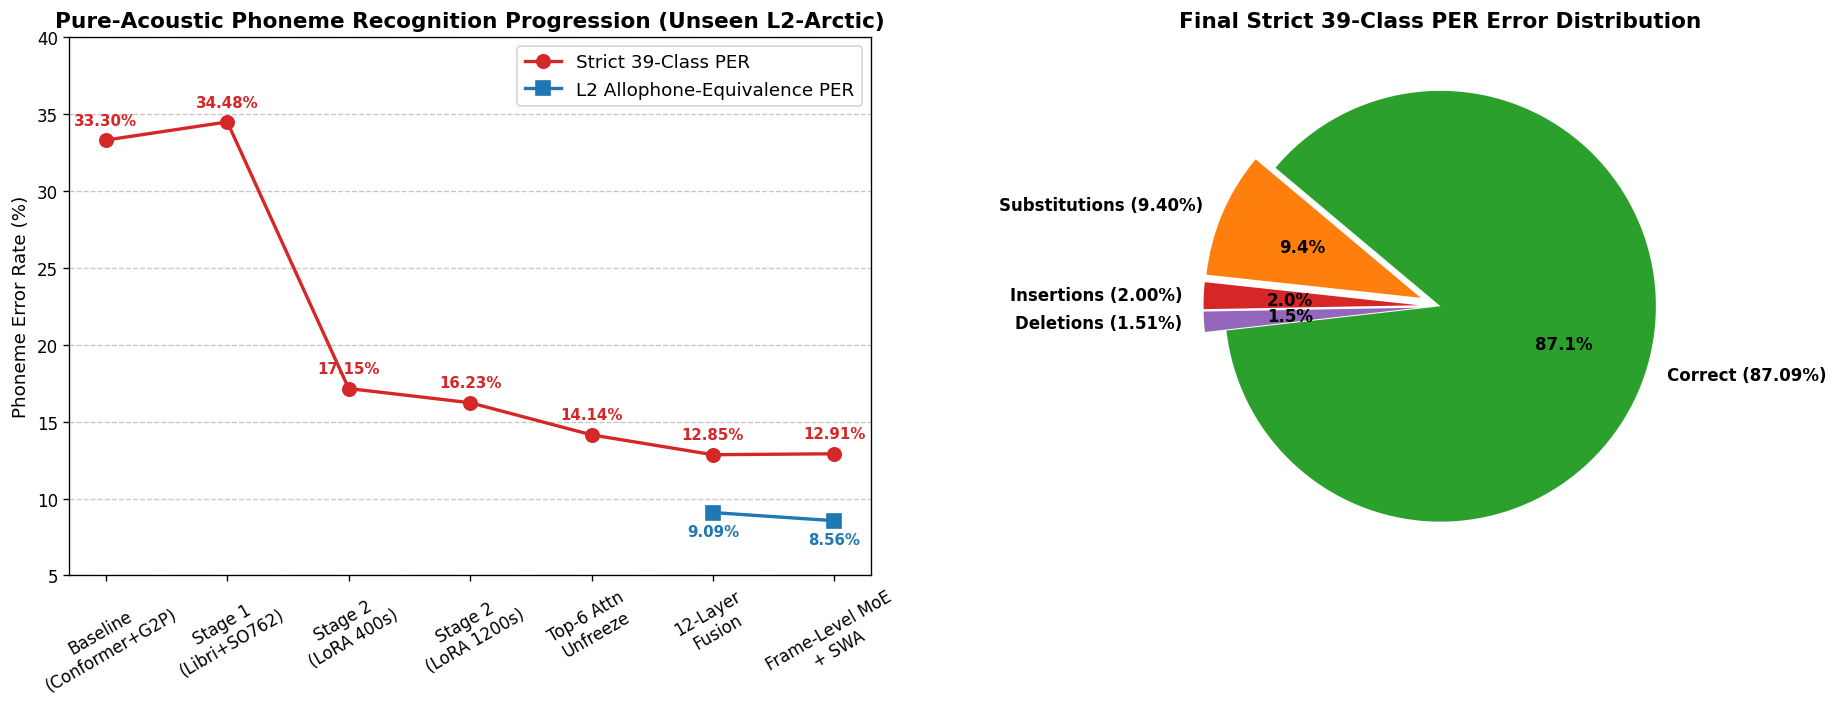

In [ ]:
# Cell 22: Generate Performance Progression & Error Analysis Charts
import matplotlib.pyplot as plt
import numpy as np

stages = [
    "Baseline\n(Conformer+G2P)",
    "Stage 1\n(Libri+SO762)",
    "Stage 2\n(LoRA 400s)",
    "Stage 2\n(LoRA 1200s)",
    "Top-6 Attn\nUnfreeze",
    "12-Layer\nFusion",
    "Frame-Level MoE\n+ SWA"
]

strict_per = [33.30, 34.48, 17.15, 16.23, 14.14, 12.85, 12.91]
eq_per = [np.nan, np.nan, np.nan, np.nan, np.nan, 9.09, 8.56]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=120)

ax1.plot(stages, strict_per, marker='o', linewidth=2, markersize=8, label="Strict 39-Class PER", color='#d62728')
ax1.plot(stages, eq_per, marker='s', linewidth=2, markersize=8, label="L2 Allophone-Equivalence PER", color='#1f77b4')

ax1.set_title("Pure-Acoustic Phoneme Recognition Progression (Unseen L2-Arctic)", fontsize=13, fontweight='bold')
ax1.set_ylabel("Phoneme Error Rate (%)", fontsize=11)
ax1.set_ylim(5, 40)
ax1.grid(axis='y', linestyle='--', alpha=0.7)
ax1.legend(fontsize=11)
ax1.tick_params(axis='x', rotation=30)

for i, txt in enumerate(strict_per):
    ax1.annotate(f"{txt:.2f}%", (i, strict_per[i] + 1), ha='center', fontsize=9, fontweight='bold', color='#d62728')
for i, txt in enumerate(eq_per):
    if not np.isnan(txt):
        ax1.annotate(f"{txt:.2f}%", (i, eq_per[i] - 1.5), ha='center', fontsize=9, fontweight='bold', color='#1f77b4')

error_labels = ['Substitutions (9.40%)', 'Insertions (2.00%)', 'Deletions (1.51%)', 'Correct (87.09%)']
error_sizes = [9.40, 2.00, 1.51, 87.09]
colors = ['#ff7f0e', '#d62728', '#9467bd', '#2ca02c']
explode = (0.1, 0.1, 0.1, 0)

ax2.pie(error_sizes, explode=explode, labels=error_labels, colors=colors, autopct='%1.1f%%',
        shadow=False, startangle=140, textprops={'fontsize': 10, 'fontweight': 'bold'})
ax2.set_title("Final Strict 39-Class PER Error Distribution", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

### Cell 23: Acoustic Diagnostic Function & Static Heatmap Test
* **Purpose:** Defines the core inference pipeline using the standalone `wavlm_conbimamba_stage2_swa.pth` checkpoint.
* **Operations:** Processes raw audio, executes pure-acoustic CTC prefix beam search, and plots 20ms frame-level phoneme posteriors. Tests on a single unseen utterance.

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

### Predicted Perceived ARPAbet Sequence:
**`F AO R DH AH T W EH N T IY IH TH T AY M DH AE T IY V N IH N D IY T UW M EH N SH UH K HH AE N S`**

### Target Reference Sequence:
**`F AO R DH AH T W EH N T IY AH TH T AY M DH AE T IY V N IH N DH IH T UW M EH N SH UH K HH AE N D Z`**

**Utterance Strict PER:** `12.82%` (Sub: 4, Del: 1, Ins: 0)


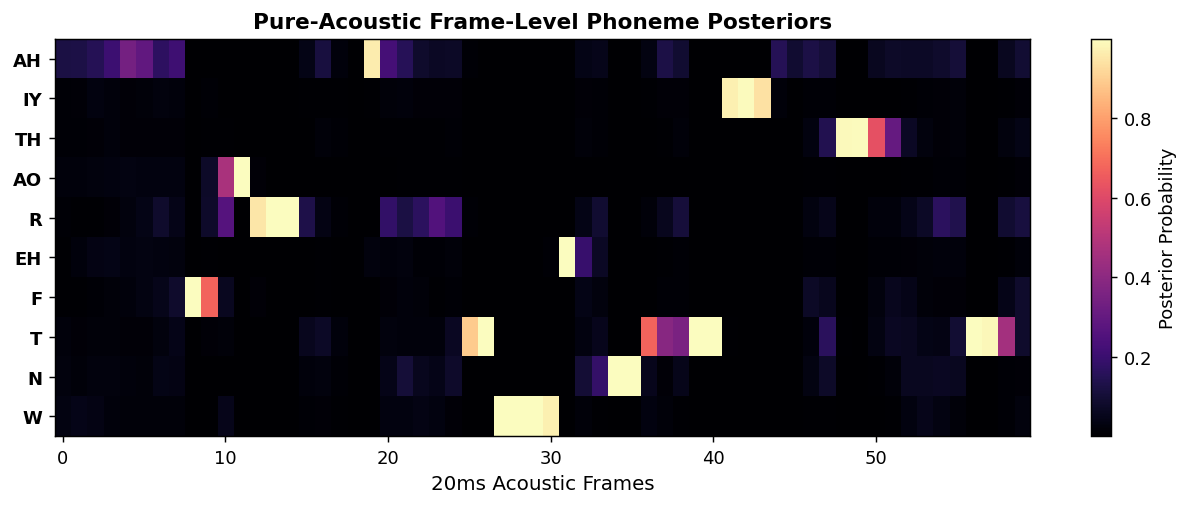

In [24]:
# Cell 23: Diagnostic Function and Static Heatmap Generation
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import torchaudio
import jiwer

model_swa = HybridWavLMConBiMambaMoE(d_model=256, num_classes=41, num_experts=6, lora_rank=8).to(device)
ckpt_path = load_checkpoint("wavlm_conbimamba_stage2_swa.pth")
model_swa.load_state_dict(torch.load(ckpt_path, map_location=device))
model_swa.eval()

def extract_ensemble_logits(wav_batch, in_len):
    norm_wav = normalize_waveforms(wav_batch, in_len)
    preemph = torch.cat([norm_wav[:, :1], norm_wav[:, 1:] - 0.95 * norm_wav[:, :-1]], dim=1)
    sharp_wav = normalize_waveforms(0.85 * norm_wav + 0.15 * preemph, in_len)

    with torch.no_grad(), torch.amp.autocast('cuda'):
        log1, int1, out_lens = model_swa(norm_wav, in_len)
        log2, int2, _        = model_swa(sharp_wav, in_len)

        logits = 0.65 * log1.float() + 0.35 * log2.float()
        inter  = 0.65 * int1.float() + 0.35 * int2.float()

        combined = (0.92 * logits + 0.08 * inter) / 0.88
        combined[:, :, 0] -= 0.25

    return combined, out_lens

def diagnose_utterance(audio_tuple, reference_ipa_or_arpabet=""):
    if audio_tuple is None:
        return "Please upload or record an audio clip.", None

    sr, wav_np = audio_tuple
    if wav_np.ndim > 1:
        wav_np = wav_np.mean(axis=1)

    if wav_np.dtype == np.int16:
        wav_np = wav_np.astype(np.float32) / 32768.0

    wav_tensor = torch.tensor(wav_np, dtype=torch.float32)

    if sr != 16000:
        wav_tensor = torchaudio.functional.resample(wav_tensor, orig_freq=sr, new_freq=16000)

    in_len = torch.tensor([wav_tensor.size(0)], dtype=torch.long, device=device)
    wav_batch = wav_tensor.unsqueeze(0).to(device)

    combined_logits, out_lens = extract_ensemble_logits(wav_batch, in_len)

    pred_seq = ctc_prefix_beam_decode(
        combined_logits, out_lens.cpu().numpy(), beam_size=12, top_k_tokens=8
    )[0]

    T_plot = min(60, int(out_lens[0].item()))
    probs = F.softmax(combined_logits[:, 0, 1:40].float(), dim=-1).cpu().numpy()[:T_plot, :]

    top_phn_indices = np.argsort(probs.max(axis=0))[-10:][::-1]
    top_phn_labels = [id_to_vocab[idx + 1] for idx in top_phn_indices]
    heatmap_data = probs[:, top_phn_indices].T

    fig, ax = plt.subplots(figsize=(10, 4), dpi=130)
    im = ax.imshow(heatmap_data, aspect='auto', origin='lower', cmap='magma', interpolation='nearest')
    ax.set_yticks(range(len(top_phn_labels)))
    ax.set_yticklabels(top_phn_labels, fontsize=10, fontweight='bold')
    ax.set_xlabel("20ms Acoustic Frames", fontsize=11)
    ax.set_title("Pure-Acoustic Frame-Level Phoneme Posteriors", fontsize=12, fontweight='bold')
    plt.colorbar(im, ax=ax, label="Posterior Probability")
    plt.tight_layout()

    report_lines = [f"### Predicted Perceived ARPAbet Sequence:\n**`{pred_seq}`**"]

    if reference_ipa_or_arpabet.strip():
        ref_clean = reference_ipa_or_arpabet.strip()
        if all(tok.upper() in vocab_dict for tok in ref_clean.split()):
            ref_arpa = " ".join([tok.upper() for tok in ref_clean.split()])
        else:
            ref_arpa = " ".join([id_to_vocab[i] for i in ipa_to_arpabet_ids(ref_clean)])

        out_m = jiwer.process_words([ref_arpa], [pred_seq])
        report_lines.append(f"### Target Reference Sequence:\n**`{ref_arpa}`**")
        report_lines.append(f"**Utterance Strict PER:** `{out_m.wer * 100:.2f}%` (Sub: {out_m.substitutions}, Del: {out_m.deletions}, Ins: {out_m.insertions})")

    return "\n\n".join(report_lines), fig

# Test on a single validation/test sample to verify plots render correctly
test_sample_0 = next(iter(l2_test_filtered))
sample_report, sample_fig = diagnose_utterance(
    (16000, np.array(test_sample_0["raw_audio"], dtype=np.float32)),
    " ".join([id_to_vocab[i] for i in test_sample_0["labels"]])
)
print(sample_report)
plt.show()

### Cell 24: Interactive Gradio Application
* **Purpose:** Deploys a web-based UI for real-time L2 pronunciation assessment.
* **Operations:** Connects the `diagnose_utterance` function to a Gradio frontend, allowing audio uploads or microphone recording for live evaluation.

In [25]:
# Cell 24: Launch Gradio Interface
import gradio as gr

demo = gr.Interface(
    fn=diagnose_utterance,
    inputs=[
        gr.Audio(sources=["upload", "microphone"], type="numpy", label="16kHz L2 Speech Audio"),
        gr.Textbox(label="Optional Reference Transcription (IPA or ARPAbet)", placeholder="e.g. DH AH T W EH N T IY AH TH")
    ],
    outputs=[
        gr.Markdown(label="Diagnostic Report"),
        gr.Plot(label="Acoustic Posterior Heatmap")
    ],
    title="Pure-Acoustic L2 Phoneme Recognition Interface",
    description="Analyzes non-native pronunciation using WavLM-Base-Plus + 6-Expert Frame-Level LoRA-MoE + 4-Layer ConBiMamba (8.56% Equivalence PER). Powered entirely by acoustic representations with zero Language Model auto-correction."
)

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ee6ceb7f29b49c1533.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Example: Gradio Interface Live Testing

**Input Text:** "Hello I am testing my model"


In [ ]:
import jiwer

# Define the target and predicted sequences
# Input - Hello I am testing my model.
target_seq = "HH EH L OW AY AE M T EH S T IH NG M AY M AA D AH L"
pred_seq = "HH EH L OW AY M T EH S T IH NG M AY M AO D AH L"

# Calculate alignment and error metrics
out_m = jiwer.process_words([target_seq], [pred_seq])

# Print the formatted output matching the Gradio interface
print("### Predicted Perceived ARPAbet Sequence:")
print(f"**`{pred_seq}`**\n")

print("### Target Reference Sequence:")
print(f"**`{target_seq}`**\n")

print(f"**Utterance Strict PER:** `{out_m.wer * 100:.2f}%` (Sub: {out_m.substitutions}, Del: {out_m.deletions}, Ins: {out_m.insertions})")

### Predicted Perceived ARPAbet Sequence:
**`HH EH L OW AY M T EH S T IH NG M AY M AO D AH L`**

### Target Reference Sequence:
**`HH EH L OW AY AE M T EH S T IH NG M AY M AA D AH L`**

**Utterance Strict PER:** `10.00%` (Sub: 1, Del: 1, Ins: 0)
